In [184]:
import pandas as pd
import seaborn as sns

HW :- do 50 qns on matplotlib, pandas, numpy

In [185]:
data = pd.read_csv("/insurance.csv")

In [186]:
data

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86
...,...,...,...,...,...,...,...
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95


   age     sex   bmi  children smoker     region  expenses
0   19  female  27.9         0    yes  southwest  16884.92
1   18    male  33.8         1     no  southeast   1725.55
2   28    male  33.0         3     no  southeast   4449.46
3   33    male  22.7         0     no  northwest  21984.47
4   32    male  28.9         0     no  northwest   3866.86


<Axes: xlabel='bmi', ylabel='expenses'>

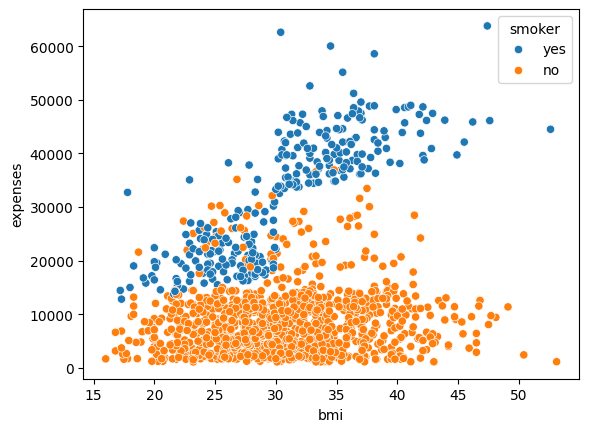

In [187]:
#visualize
print(data.head())
sns.scatterplot(x=data["bmi"],y=data["expenses"], hue=data["smoker"])

Explain head() in detail.

In [188]:
X = data.drop(columns=["expenses", "region"])
y = data["expenses"]

X["sex"] = X["sex"].map({"male": 0, "female": 1})
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})

taking just 4 data using head.
selecting specific rows and columns, selecting- custom
visulizing differently.

Data processing -mapping - categorical valyes not understood by model so make it binary. Yes =1, No =0

In [189]:
x.head()

,age,sex,bmi,children,smoker
0,19,female,27.9,0,yes
1,18,male,33.8,1,no
2,28,male,33.0,3,no
3,33,male,22.7,0,no
4,32,male,28.9,0,no


CHECK MISTAKE- 0 AND 1 OF SMOKERS.

X= multiple values, x= single value

Import models, training, testing data

In [190]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
x_train.head()

,age,sex,bmi,children,smoker
560,46,1,20.0,2,0
1285,47,1,24.3,0,0
1142,52,1,24.9,0,0
969,39,1,34.3,5,0
486,54,1,21.5,3,0


Select model - for linear regression, creating of model


In [191]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)

LinearRegression()


give testing data (hidden data) to model



give testing data (hidden data) to model

predicting value of y using x

y test is the actual value, y pred is predicted value

In [192]:
y_pred = model.predict(x_test)

give testing data
(hidden data) to model

evaluate performance of model

In [193]:
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.7811077124524389

p- columns, n- rows, r2 - score.

In [203]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)

n = x_test.shape[0]
p = x_test.shape[1]
adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
adjusted_r2

0.7769303787206152

In [ ]:
# @title Licensed under the Apache License, Version 2.0 (the "License");
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

### Install SDK

Install the SDK from [PyPI](https://github.com/googleapis/python-genai). It's recommended to always use the latest version.

In [ ]:
%pip install -U -q "google-genai>=2.30.0"  # 2.30+ for Gemini 4 Argon and long decode support

### Setup your API key

To run the following cell, your API key must be stored in a Colab Secret named `GEMINI_API_KEY`. If you don't already have an API key or you aren't sure how to create a Colab Secret, see [Authentication ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](../quickstarts/Authentication.ipynb) for a walkthrough.

In [ ]:
from google.colab import userdata

GEMINI_API_KEY = userdata.get('GEMINI_API_KEY')


### Initialize SDK client

With the new SDK, now you only need to initialize a client with your API key (or OAuth if using [Vertex AI](https://cloud.google.com/vertex-ai)). The model is now set in each call.

In [ ]:
from google import genai
from google.genai import types

client = genai.Client(api_key=GEMINI_API_KEY)

### Choose a model

Select the model you want to use in this guide. You can either select one from the list or enter a model name manually. If you are not sure what to choose, stick with the default `gemini-3.8-flash` model.

Feel free to select [Gemini 4 Argon](https://ai.google.dev/gemini-api/docs/models/gemini-4-argon) (`gemini-4-argon`) if you want to try Google's most powerful frontier reasoning model, or [Gemini 3.1 Pro](https://ai.google.dev/gemini-api/docs/models/gemini-3.1-pro-preview), keeping in mind that neither has a free tier.

For a full overview of all Gemini models, check the [documentation](https://ai.google.dev/gemini-api/docs/models/gemini).

In [ ]:
MODEL_ID = "gemini-3.8-flash" # @param ["gemini-4-argon", "gemini-3.1-pro-preview", "gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.6-flash", "gemini-3.5-flash-lite", "gemini-2.5-pro"] {"allow-input": true, "isTemplate": true}

<a name="text_prompt"></a>
## Send text prompts

Use the `interactions.create` method to generate responses from text-only input.

You can pass text directly to `input` parameter and use the .text property to get the text content of the response. Note that the .text field will work when there's only one part in the out

In [ ]:
from IPython.display import Markdown

interaction = client.interactions.create(
    model=MODEL_ID,
    input="Explain how AI works in a few words",
)

# The response is an Interaction object containing a list of steps.
# Each step represents a part of the model's response.
# Let's look at what the steps contain:
print(f"Number of steps: {len(interaction.steps)}")
for j, step in enumerate(interaction.steps):
    print(f"  Step {j}: type={step.type}")

In [ ]:
interaction.output_text

The last step (index `-1`) usually contains the model's text output. You can also access it it `.output_text`.

In [ ]:
# Access the text response:
Markdown(interaction.steps[-1].content[0].text)

In [ ]:
# Access the text response with output_text:
Markdown(interaction.output_text)

See [below](#thinking) to learn how to manage the other part (the `thought` part).

<a name="system_instructions"></a>
## Add system instructions

You can also add system instructions to steer the behavior of the model. Note that system instructions will be set for the whole chain of interaction and not per turn.

In [ ]:
system_instruction = "You are a pirate and are explaining things to 5 years old kids."

interaction = client.interactions.create(
    model=MODEL_ID,
    input="Explain how AI works",
    system_instruction=system_instruction,
)

Markdown(interaction.output_text)

<a name="count_tokens"></a>
## Count tokens

Tokens are the basic inputs to the Gemini models. You can use the `count_tokens` method to calculate the number of input tokens before sending a request to the Gemini API.

In [ ]:
response = client.models.count_tokens(
    model=MODEL_ID,
    contents="What's the highest mountain in Africa?",
)

print(f"This prompt was worth {response.total_tokens} tokens.")

<a name="parameters"></a>
## Configure model parameters

You can include parameter values in each call you send to a model using `generation_config`.

In [ ]:
interaction = client.interactions.create(
    model=MODEL_ID,
    input="Tell me how the internet works, but pretend I'm a puppy who understands only dog-related analogies.",
    generation_config={
        "max_output_tokens": 1000,  # In Gemini 3, this includes both thought and response tokens
    },
)

Markdown(interaction.output_text)

<a name="thinking"></a>
## Control the thinking process

Gemini models support configurable **thinking levels** that control how much internal reasoning the model performs before responding. Higher thinking levels produce better results for complex tasks but use more tokens and take longer.

To see the model thoughts, you need to check the `steps` that are of type `thought`. This will not give you the full details of what the model "thought", but you'll have a summary to help you understand how the model arrived to its conclusion.

Available thinking levels: `"minimal"` (supported on Gemini 3 Flash models), `"low"`, `"medium"`, `"high"`. Note that `gemini-4-argon` supports `"low"`, `"medium"` (default), and `"high"`.

See [Get started with thinking](./Get_started_thinking.ipynb) for a complete guide.

In [ ]:
from IPython.display import display, Markdown

thinking_level = "high" # @param ["minimal", "low", "medium", "high"]

interaction = client.interactions.create(
    model=MODEL_ID,
    input="A man moves his car to a hotel and tells the owner he's bankrupt. Why?",
    generation_config={"thinking_level": thinking_level},
)

# Display the thinking process and the answer
for step in interaction.steps:
    if step.type == "thought":
        print("💭 Thought:", getattr(step, "text", "")[:200] if hasattr(step, "text") else "(thinking...)")
    elif step.type == "model_output" and step.content:
        display(Markdown(step.content[0].text))


<a name="thought_signatures"></a>
### Thought signatures

Gemini models include a `thought_signature` in responses. This is managed automatically by the SDK, but here's what happens behind the scenes:

In [ ]:
# Create an interaction with thinking enabled to get a thought signature
interaction_with_thinking = client.interactions.create(
    model=MODEL_ID,
    input="What was the weather during the last soccer world cup final?",
)

# Print the thought signature from the response
for step in interaction_with_thinking.steps:
    if step.type == "thought" and hasattr(step, 'signature') and step.signature:
        # Only display the first 100 characters to keep notebook size manageable
        print(f"Thought signature: {step.signature[:100]}...")
        break
else:
    print("No thought signature found in this response.")


The signature helps the model remember not only what was said before, but also what it *thought* before and what it got from tools and function calls.

For example: if you ask for today's temperature, the model might use Google Search and learn it's 25°C *and* that humidity is 60%. If you then ask about humidity, it can recall this from the first call without making a new request.

More details on [thought signatures](https://ai.google.dev/gemini-api/docs/gemini-3?thinking=explicit#thought_signatures) in the documentation.

<a name="multimodal_prompt"></a>
## Send multimodal prompts

Gemini models have strong multimodal understanding capabilities. You can include text, [PDF documents ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](../quickstarts/PDF_Files.ipynb), images, [audio ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](../quickstarts/Audio.ipynb) and [videos ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](../quickstarts/Video_understanding.ipynb) in your prompt requests and get text or code responses. Check the [File API](#file_api) section below for more examples.

In this first example, you're going to give the model an image via an URI, and ask Gemini to generate a short blog post based on it.


> **Note:** Passing the HTTP URI directly should work, but is broken ATM. We are switching to the File API for now.


In [ ]:
from IPython.display import display, Markdown

# Download the image
!wget -q -O generated_elephants_giraffes_zebras_sunset.jpg https://storage.googleapis.com/generativeai-downloads/images/generated_elephants_giraffes_zebras_sunset.jpg
image_filename = "generated_elephants_giraffes_zebras_sunset.jpg"

# Upload the image to the Gemini File API
file_upload = client.files.upload(file=image_filename)
interaction = client.interactions.create(
    model=MODEL_ID,
    input=[
        {
            "type": "image",
            "uri": file_upload.uri,
        },
        {"type": "text", "text": "What do you see in this image? Describe it briefly."},
    ],
)
display(Markdown(interaction.output_text))

You can also download an image and send it as base64-encoded data. This is useful when you need to preprocess the image or when the URL is not publicly accessible:

In [ ]:
import requests
import pathlib
from PIL import Image
from IPython.display import display

IMG = "https://storage.googleapis.com/generativeai-downloads/data/jetpack.png" # @param {type: "string"}

img_bytes = requests.get(IMG).content

img_path = pathlib.Path('jetpack.png')
img_path.write_bytes(img_bytes)

# Display the image
display(Image.open(img_path).resize((400, 400)))

In [ ]:
import base64
from IPython.display import display, Markdown

# Encode the image as base64 to send it inline with the prompt
img_b64 = base64.b64encode(img_path.read_bytes()).decode("utf-8")

interaction = client.interactions.create(
    model=MODEL_ID,
    input=[
        {"type": "image", "data": img_b64, "mime_type": "image/png"},
        {"type": "text", "text": "Write a short and engaging blog post based on this picture."},
    ],
)

display(Markdown(interaction.output_text))

<a name="image_gen"></a>
## Generate images

Gemini models can also generate images as part of their response. Use `response_format` to request both text and image outputs. You need to use a model that supports image generation (like `gemini-nano-banana-2.1`) which has a free tier.

The generated image can either be recovered by looping over the `steps` or using `output_image`.

In [195]:
from IPython.display import Image, Markdown, display
import base64

IMAGE_MODEL = "gemini-nano-banana-2.1" # @param ["gemini-nano-banana-2.1", "gemini-3.1-pro-image-preview", "gemini-3.1-flash-image-preview", "gemini-2.5-flash-image"] {"allow-input":true}

interaction = client.interactions.create(
    model=IMAGE_MODEL,
    input="Generate an image of a cat wearing a top hat in a library.",
    response_format=[
        {"type": "text"},
        {
          "type": "image",
          "mime_type": "image/jpeg",
          "aspect_ratio": "16:9",
          "image_size": "2K"
        },
    ],
)

# Display all content from model output steps
for step in interaction.steps:
    if step.type == "model_output":
        for content in step.content:
            if content.type == "image" and hasattr(content, 'data') and content.data:
                display(Image(data=base64.b64decode(content.data), format="jpeg"))
            elif content.type == "text" and content.text:
                display(Markdown(content.text))

# Or more simply:
# display(Image(data=base64.b64decode(interaction.output_image.data)))

NameError: name 'client' is not defined

<a name="safety_filters"></a>
## Safety filters

Gemini models have built-in safety filters that are always active. The models manage safety automatically — there are no configurable safety settings to set. For more details, see the [safety documentation](https://ai.google.dev/gemini-api/docs/safety-settings).

<a name="chat"></a>
## Chain mutltiple requests in a conversation

The Interactions API enables multi-turn conversations using `previous_interaction_id` to chain interactions. The server manages conversation state — you just pass the ID from the previous turn and all the history of the previous turns will be kept.

In [ ]:
from IPython.display import Markdown

# First turn: ask a question
turn_1 = client.interactions.create(
    model=MODEL_ID,
    input="Why is the same side of the Moon always visible from Earth? Keep it short.",
)

Markdown(turn_1.output_text)


Use `previous_interaction_id` to send follow-up messages. The model remembers the full conversation context.

In [ ]:
# Follow-up question referencing the previous answer
turn_2 = client.interactions.create(
    model=MODEL_ID,
    input="Interesting! Has any human or spacecraft actually seen the far side?",
    previous_interaction_id=turn_1.id,
)

Markdown(turn_2.output_text)


### Switch models mid-conversation

One powerful feature of the Interactions API is that you can **switch models within the same conversation**. Here, you'll switch to an image generation model to create a visual inspired by the conversation:


In [ ]:
IMAGE_MODEL = "gemini-nano-banana-2.1" # @param ["gemini-nano-banana-2.1", "gemini-3.1-pro-image-preview", "gemini-3.1-flash-image-preview", "gemini-2.5-flash-image"] {"allow-input":true}

# Continue the same conversation with an image generation model
turn_3 = client.interactions.create(
    model=IMAGE_MODEL,
    input="Based on the previous conversation, generate an image of the far side of the Moon as seen from a spacecraft.",
    previous_interaction_id=turn_2.id,
)

display(Image(data=base64.b64decode(turn_3.output_image.data)))

### Save and resume a conversation

With the Interactions API, conversation state is managed server-side. You just need to save the `interaction.id` to resume a conversation later — even with a different model.

Conversation state is retained for **24 hours** after the last interaction.

If you want to save the conversation for a longer duration (or check in detail what happened during all steps), you can extract the full conversation history by calling `client.interactions.get` and following `previous_interaction_id` back to the first turn:

In [ ]:
# Retrieve the full conversation history by following previous_interaction_id
# Filter out model-specific thought steps so you can resume across models
saved_steps = []
current_id = turn_3.id
while current_id:
    turn = client.interactions.get(id=current_id)
    turn_steps = [step for step in turn.steps if step.type != "thought"]
    saved_steps = turn_steps + saved_steps
    current_id = turn.previous_interaction_id

print(f"Saved {len(saved_steps)} steps.")
print(f"First step: {saved_steps[0]}")

Here, filtering out the internal `thought` steps (whose signatures are model-specific) leaves 7 `user_input` and `model_output` steps across the 3 turns — including the generated image from the third turn.

When you want to resume the conversation later, just pass `saved_steps` along with your new message:

In [ ]:
resumed = client.interactions.create(
    model=MODEL_ID,
    input=saved_steps + [{
        "type": "user_input",
        "content": [{
            "type": "text",
            "text": "Describe the image you just created in two sentences, then translate that description into French."
        }]
    }]
)

Markdown(resumed.output_text)

In [ ]:
# Ensure client and dependencies are defined
from google.colab import userdata
from google import genai

try:
    client
except NameError:
    GEMINI_API_KEY = userdata.get('GEMINI_API_KEY')
    client = genai.Client(api_key=GEMINI_API_KEY)

try:
    MODEL_ID
except NameError:
    MODEL_ID = "gemini-3.8-flash"

# The model remembers the full conversation, even across model swaps
resumed_2 = client.interactions.create(
    model=MODEL_ID,
    input="What was my very first question?",
    previous_interaction_id=resumed.id,
)

Markdown(resumed_2.output_text)

As expected, the first question from `turn_1` (*"Why is the same side of the Moon always visible from Earth? Keep it short."*) was returned.

<a name="json"></a>
## Generate JSON

The [controlled generation](https://ai.google.dev/gemini-api/docs/json-mode) feature lets you constrain model output to JSON format. Pass a `response_format` with a JSON schema — you can use Pydantic models to define the schema.

Note the use of `model_json_schema()` to automatically convert the Pydantic model into a JSON Schema that the API accepts. This is the recommended pattern as it handles nested types, enums, and optional fields correctly.

In [196]:
from pydantic import BaseModel
import json
from typing import List

class Recipe(BaseModel):
    recipe_name: str
    recipe_description: str

class RecipeList(BaseModel):
    recipes: List[Recipe]

interaction = client.interactions.create(
    model=MODEL_ID,
    input="List 3 popular cookie recipes.",
    response_format={
        "type": "text",
        "mime_type": "application/json",
        "schema": RecipeList.model_json_schema(),
    },
)

recipes = json.loads(interaction.output_text)
print(json.dumps(recipes, indent=4))

NameError: name 'client' is not defined

<a name="stream"></a>
## Generate content stream

By default, the model returns a response after completing the entire generation process. You can also stream the response as it is being generated by passing `stream=True`. The response is then delivered incrementally via events.


When streaming, the response is delivered as a series of events with `delta` objects containing incremental text:


In [ ]:
for event in client.interactions.create(
    model=MODEL_ID,
    input="Tell me a story about a lonely robot who finds friendship in a most unexpected place.",
    stream=True,
):
    if hasattr(event, "delta") and hasattr(event.delta, "text") and event.delta.text:
        print(event.delta.text, end="")


<a name="async"></a>
## Send asynchronous requests

`client.aio` exposes all the analogous async methods for non-blocking API calls.

For example, `client.aio.interactions.create` is the async version of `client.interactions.create`.

More details in the [dedicated guide ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Asynchronous_requests.ipynb).

In [ ]:
interaction = await client.aio.interactions.create(
    model=MODEL_ID,
    input="Compose a sonnet about a cat riding a bicycle through a field of sunflowers.",
)

Markdown(interaction.output_text)

<a name="file_api"></a>
## Upload files

Now that you've seen how to send multimodal prompts, try uploading files to the API of different multimedia types. For small images, such as the previous multimodal example, you can point the Gemini model directly to a local file when providing a prompt. When you've larger files, many files, or files you don't want to send over and over again, you can use the [File Upload API](https://ai.google.dev/gemini-api/docs/files), and then pass the file by reference.

More examples and details in the [File API guide ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./File_API.ipynb), or the guides dedicated to [Audio![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Audio.ipynb), [Video![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Video_understanding.ipynb) or [Image/Spatial![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Spatial_understanding.ipynb) understanding.

### Upload a large text file

Let's start by uploading a text file. In this case, you'll use a 400 page transcript from [Apollo 11](https://www.nasa.gov/history/alsj/a11/a11trans.html).

In [ ]:
# Download the text file
text_url = "https://storage.googleapis.com/generativeai-downloads/data/a11.txt"
!wget -q -O a11.txt {text_url}
text_path = "a11.txt"
print(f"Downloaded: {text_path}")

In [197]:
# Upload the file using the API
file_upload = client.files.upload(file=text_path)
interaction = client.interactions.create(
    model=MODEL_ID,
    input=[
        {"type": "document", "uri": file_upload.uri},
        {"type": "text", "text": "Can you give me a short, concise summary of this information please?"},
    ],
)
Markdown(interaction.output_text)

NameError: name 'client' is not defined

### Upload an image file

You can also upload images so that it's easier to use them multiple time.


In [ ]:
import pathlib, requests

# Download a sample image
IMG_URL = "https://storage.googleapis.com/generativeai-downloads/data/jetpack.png"
img_path = pathlib.Path("jetpack.png")
if not img_path.exists():
    img_path.write_bytes(requests.get(IMG_URL).content)

# Upload the file using the API
file_upload = client.files.upload(file=img_path)

interaction = client.interactions.create(
    model=MODEL_ID,
    input=[
        {"type": "image", "uri": file_upload.uri},
        {"type": "text", "text": "Describe this image in a few sentences."},
    ],
)

display(Markdown(interaction.output_text))

You can also control how much detail the model extracts from the image using `media_resolution` — see the [media resolution section](#media_resolution) below.

### Use a PDF file

You can pass a PDF URL directly in your prompt, just like images. And this time instead of using the file API, let's directly pass its URI.

In [ ]:
interaction = client.interactions.create(
    model=MODEL_ID,
    input=[
        {
            "type": "document",
            "uri": "https://arxiv.org/pdf/1706.03762",
            "mime_type": "application/pdf",
        },
        {"type": "text", "text": "What is this paper about? Summarize the key contributions."},
    ],
)

display(Markdown(interaction.output_text))

### Upload an audio file

In this case, you'll use a [sound recording](https://www.jfklibrary.org/asset-viewer/archives/jfkwha-006) of President John F. Kennedy’s 1961 State of the Union address.

In [ ]:
# Download the audio file
audio_url = "https://storage.googleapis.com/generativeai-downloads/data/State_of_the_Union_Address_30_January_1961.mp3"
!wget -q -O sotu.mp3 {audio_url}
audio_path = "sotu.mp3"
print(f"Downloaded: {audio_path}")

In [ ]:
# Upload the file using the API
file_upload = client.files.upload(file=audio_path)

interaction = client.interactions.create(
    model=MODEL_ID,
    input=[
        {"type": "text", "text": "Listen to the following file and write a short summary."},
        {"type": "document", "uri": file_upload.uri},
    ],
)

Markdown(interaction.output_text)

### Upload a video file

In this case, you'll use a short clip of [Big Buck Bunny](https://peach.blender.org/about/).

In [ ]:
# Download the video file
VIDEO_URL = "https://storage.googleapis.com/generativeai-downloads/videos/Big_Buck_Bunny.mp4"
video_file_name = "BigBuckBunny_320x180.mp4"

import urllib.request
urllib.request.urlretrieve(VIDEO_URL, video_file_name)
print(f"Downloaded: {video_file_name}")

Let's start by uploading the video file.

In [198]:
# Upload the file using the API
video_file = client.files.upload(file=video_file_name)
print(f"Started upload: {video_file.uri}")

NameError: name 'client' is not defined

> **Note:** The state of the video is important. The video must finish processing, so do check the state. Once the state of the video is `ACTIVE`, you're able to pass it into `interactions.create`.

In [ ]:
import time

# Check the file processing state
while video_file.state == "PROCESSING":
    print('Waiting for video to be processed.')
    time.sleep(10)
    video_file = client.files.get(name=video_file.name)

if video_file.state == "FAILED":
  raise ValueError(video_file.state)

print(f'Video processing complete: ' + video_file.uri)

In [ ]:
print(video_file.state)

In [ ]:
# Ask Gemini about the video
interaction = client.interactions.create(
    model=MODEL_ID,
    input=[
        {"type": "video", "uri": video_file.uri},
        {"type": "text", "text": "Describe this video."},
    ],
)

Markdown(interaction.output_text)

<a name="media_resolution"></a>
## Media resolution

You can specify a media resolution for image and PDF inputs, which controls how images are tokenized and how many tokens are used. This can be controlled **per file**.

| Resolution | Images | PDFs | Video |
|---|---|---|---|
| `MEDIA_RESOLUTION_HIGH` | 1120 tokens | 1120 tokens | 280 tokens/frame |
| `MEDIA_RESOLUTION_MEDIUM` | 560 tokens | 560 tokens (default for PDFs) | 70 tokens/frame |
| `MEDIA_RESOLUTION_LOW` | 280 tokens | 280 tokens | 70 tokens/frame |
| `MEDIA_RESOLUTION_UNSPECIFIED` (default) | Same as HIGH for images | Same as MEDIUM for PDFs | Same as MEDIUM for video |

Note that these are maximums, and the actual token usage will usually be slightly lower (by approx 10%).

Here's an example using media resolution to control token usage:

In [ ]:
import pathlib
from google.genai import types

# Upload to File API
sample_image = client.files.upload(file=img_path)

media_resolution = 'MEDIA_RESOLUTION_HIGH'

# Use generate_content for media_resolution (not yet in Interactions API)
interaction = client.models.generate_content(
    model=MODEL_ID,
    contents=[
        sample_image,
        "Describe this image in detail."
    ],
    config=types.GenerateContentConfig(
        media_resolution=media_resolution,
    ),
)

print(f"The image is worth {interaction.usage_metadata.candidates_token_count} tokens.")

<a name="grounding"></a>
## Grounding

The Gemini API give you multiple ways to ground your requests, including Google search, maps, youtube, and url context.

For more details information and examples, check the [Grounding ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Grounding.ipynb) notebook.

In [ ]:
from IPython.display import Markdown, HTML, display

interaction = client.interactions.create(
    model=MODEL_ID,
    input="Who's the current Magic the gathering world champion?",
    tools=[{"type": "google_search"}],
)

display(Markdown(interaction.output_text))


Note that you should always display the grounding `rendered_content` when using search grounding.

Check out the [Search grounding ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Search_Grounding.ipynb) dedicated guide for more details and examples.

In [ ]:
# Find each step with type "google_search_result"
for step in interaction.steps:
    if step.type == "google_search_result":
        # The result is a list, so access the first element and display its HTML content
        display(HTML(step.result[0].search_suggestions))


<a name="maps"></a>
### Use Google Maps grounding

[Google Maps grounding](https://ai.google.dev/gemini-api/docs/maps-grounding) allows you to easily incorporate location-aware functionality into your applications. When a prompt has context related to Maps data, the Gemini model uses Google Maps to provide factually accurate and fresh answers that are relevant to the specified location or general area.

To enable grounding with Google Maps, add the `google_maps` tool in the  `tool` argument of `interactions.create`.


In [ ]:
from IPython.display import display, Markdown

# Google Maps grounding requires Gemini 2.5 models
interaction = client.interactions.create(
    model=MODEL_ID,
    input="Do any cafes around the Eiffel Tower in Paris do a good flat white? I will walk up to 20 minutes away",
    tools=[{"type": "google_maps"}],
)

Markdown(interaction.output_text)


All grounded outputs require sources to be displayed after the response text. Check the [grounding guide](https://ai.google.dev/gemini-api/docs/grounding) for details.


More details, including how to render the contextual Google Maps widget, check the [Google maps ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Grounding.ipynb#maps_grounding) section of the grounding notebook.

<a name="youtube_link"></a>
### Process a YouTube link

You can analyze YouTube videos by passing the URL as a `video` input. The model will fetch the video content (including audio and visual information) and use it to answer your question:

In [ ]:
interaction = client.interactions.create(
    model=MODEL_ID,
    input=[
        {
            "type": "video",
            "uri": "https://www.youtube.com/watch?v=9hE5-98ZeCg",
        },
        {"type": "text", "text": "Summarize this video"},
    ],
)

Markdown(interaction.output_text)

<a name="URL_context"></a>
### Use URL context

URL context lets you provide web URLs directly in your prompt, and the model will fetch and use their content:


In [ ]:
prompt = """
  Compare the Apollo 11 and Apollo 12 missions using information from https://en.wikipedia.org/wiki/Apollo_11
  and https://en.wikipedia.org/wiki/Apollo_12.
  Display the key differences as a table.
"""
try:
    interaction = client.interactions.create(
        model=MODEL_ID,
        input=prompt,
        tools=[{"type": "url_context"}],
    )
    display(Markdown(interaction.output_text))
except Exception as e:
    print(f"url_context tool error: {e}")
    print("Note: url_context may not be available with all models.")


<a name="function_calling"></a>
## Function calling

[Function calling](https://ai.google.dev/gemini-api/docs/function-calling) lets you connect Gemini to external tools and APIs. You describe your functions, and the model decides when and how to call them based on the user's prompt.

> **Note:** The Interactions API does not support automatic function calling (where the SDK calls the functions for you). You must handle function calls manually as shown below. For automatic function calling, use `client.models.generate_content()` — see the [Generate Content notebook](./Get_started_Generate_Content.ipynb#function_calling) for details.

See the [Function calling notebook](./Function_calling.ipynb) for a comprehensive guide.

Define a function as a tool, pass it to the model, and handle the function call response. The complete pattern has two API calls: one to get the function call, and another to return the result:


In [199]:
import json as json_lib

get_destination = {
    "type": "function",
    "name": "get_destination",
    "description": "Get the destination for a given flight",
    "parameters": {
        "type": "object",
        "properties": {
            "flight_number": {
                "type": "string",
                "description": "The flight number, e.g. AA100"
            }
        },
        "required": ["flight_number"]
    }
}

interaction = client.interactions.create(
    model=MODEL_ID,
    input="What is the destination for flight AA100?",
    tools=[get_destination],
)

# Handle the function call and return a result
for step in interaction.steps:
    if step.type == "function_call":
        print(f"Function: {step.name}, Args: {step.arguments}")
        # Return the function result to the model
        result = {"destination": "Los Angeles"}  # Mock result

        interaction = client.interactions.create(
            model=MODEL_ID,
            previous_interaction_id=interaction.id,
            input=[{
                "type": "function_result",
                "name": step.name,
                "call_id": step.id,
                "result": [{"type": "text", "text": json_lib.dumps(result)}]
            }],
            tools=[get_destination],
        )

        # Display the model's final response
        model_step = next((s for s in interaction.steps if s.type == "model_output"), None)
        if model_step and model_step.content:
            display(Markdown(model_step.content[0].text))


NameError: name 'client' is not defined

You can also use [MCP servers](https://ai.google.dev/gemini-api/docs/function-calling#mcp).

<a name="code_execution"></a>
## Code execution

[Code execution](https://ai.google.dev/gemini-api/docs/code-execution?lang=python) lets the model generate and execute Python code to answer complex questions like math, data analysis, or code generation.

You can find more examples in the [Code execution guide ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Code_Execution.ipynb).

In [ ]:
from IPython.display import Image, Markdown, Code, HTML, display

interaction = client.interactions.create(
    model=MODEL_ID,
    input="What is the sum of the first 50 prime numbers? Generate and run code for the calculation, and make sure you get all 50.",
    tools=[{"type": "code_execution"}],
)

for step in interaction.steps:
    if step.type == "model_output":
        for content in step.content:
            if content.type == "text" and content.text:
                display(Markdown(content.text))
    elif step.type == "code_execution_call":
        code = dict(step.arguments).get('code', '')
        display(HTML(f'<pre style="background-color: #1e1e1e; color: #d4d4d4; padding: 10px;">{code}</pre>'))
    elif step.type == "code_execution_result":
        if step.result:
            display(Markdown(f"**Result:** {step.result}"))

<a name="caching"></a>
## Context caching

With the Interactions API, context caching is handled automatically via **implicit caching**. When you use `previous_interaction_id` to continue a conversation or send requests with a shared prefix of at least 4,096 tokens, the server automatically reuses cached content from previous turns, reducing latency and token costs (up to a 95% discount on Gemini 4 Argon) without any manual cache management on your part.

For explicit caching use cases on Gemini 3 and Gemini 2.5 models (e.g., manually creating a cache object for a large document), use `client.models.generate_content()` with the [caching API](https://ai.google.dev/gemini-api/docs/caching). Explicit caching is not supported on Gemini 4 Argon. See the [Get started with Generate Content](./Get_started_Generate_Content.ipynb#caching) notebook for details.

<a name="embeddings"></a>
## Get embeddings

The Gemini API offers embedding models to generate embeddings for text, images, video, and other content. These resulting embeddings can then be used for tasks such as semantic search, classification, and clustering, providing more accurate, context-aware results than keyword-based approaches.

The latest model, `gemini-embedding-2`, is the first multimodal embedding model in the Gemini API. It maps text, images, video, audio, and PDFs into a unified embedding space, enabling cross-modal search, classification, and clustering across over 100 languages. For text-only use cases, `gemini-embedding-001` remains available.

You can get text embeddings for a snippet of text by using `embed_content` method.

The Gemini Embedding models produce an output with 3072 dimensions by default. However, you've the option to choose an output dimensionality between 1 and 3072. See the [embeddings documentation](https://ai.google.dev/gemini-api/docs/embeddings) or the [dedicated notebook ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Embeddings.ipynb)
for more details.

In [ ]:
EMBEDDING_MODEL_ID = "gemini-embedding-2" # @param ["gemini-embedding-2", "gemini-embedding-001"] {"allow-input":true, isTemplate: true}

In [ ]:
response = client.models.embed_content(
    model=EMBEDDING_MODEL_ID,
    contents="What is the meaning of life?"
)

print(response.embeddings)

You'll get a set of three embeddings, one for each piece of text you passed in:

In [ ]:
len(response.embeddings)

You can also see the length of each embedding is 3072, The default size.

In [ ]:
print(len(response.embeddings[0].values))
print((response.embeddings[0].values[:4], '...'))

#### Multimodal Embeddings

With `gemini-embedding-2`, you can create embeddings for text, audio,images, videos, and PDFs. See the [multimodal embeddings documentation](https://ai.google.dev/gemini-api/docs/embeddings#multimodal)
for more details.

In [ ]:
!wget -O cat.png https://storage.googleapis.com/generativeai-downloads/cookbook/image_out/cat.png -q

In [ ]:
MULTIMODAL_EMBEDDING_MODEL_ID = "gemini-embedding-2"

with open('cat.png', 'rb') as f:
    image_bytes = f.read()

result = client.models.embed_content(
    model=MULTIMODAL_EMBEDDING_MODEL_ID,
    contents=[
        types.Part.from_bytes(
            data=image_bytes,
            mime_type='image/png',
        ),
    ]
)

print(result.embeddings)

<a name="gemini4"></a>
## What's new in Gemini 4 Argon

[Gemini 4 Argon](https://ai.google.dev/gemini-api/docs/models/gemini-4-argon) (`gemini-4-argon`) is Google's newest frontier reasoning model, purpose-built for real-world software engineering, long-horizon autonomous agents, complex knowledge work, and deep scientific reasoning.

### Key highlight: 1M token output and long decode

Unlike previous models that capped output generation at 8K or 64K tokens, Gemini 4 Argon can generate **up to 1M output tokens** (`1,048,576` tokens) in a single turn, combining its internal thinking process and final response within a unified 1M token context window.

To unlock the full 1M token output capacity without running into HTTP connection timeouts or network interruptions, Gemini 4 Argon introduces **[long decode](https://ai.google.dev/gemini-api/docs/long-decode)** through background execution. The model can perform extended, uninterrupted reasoning and generation across multiple internal passes (automatically reusing prior segments via implicit caching at a 95% discount), making it possible to:
* Synthesize entire multi-file software projects and architecture plans in one turn.
* Work through exhaustive mathematical proofs and formal verifications.
* Produce complete research reports, technical books, or comprehensive legal and financial audits.

Most of this guide works as-is with Gemini 4 Argon, with the following key features and updates covered below:
* [Thinking levels only](#gemini4_thinking): `thinking_level` (`"low"`, `"medium"`, `"high"`) replaces `thinking_budget` and acts as your primary lever to control reasoning depth.
* [Long decode and 1M output tokens](#long_decode): generate past the 64K per-request cap up to `1,048,576` tokens with background execution (`background=True`).
* [Managed agents with Gemini 4 Argon](#gemini4_agents): run sandboxed multi-step tasks powered by `gemini-4-argon`.
* [Migration checklist](#gemini4migration): upgrade your codebase from Gemini 3 and 2.5 to Gemini 4 Argon.

In [ ]:
# @title Run this cell to set everything up (especially if you jumped directly to this section)
%pip install -U -q "google-genai>=2.30.0"

from google import genai
from google.colab import userdata
from IPython.display import Markdown, display

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=GEMINI_API_KEY)

# Select the Gemini 4 model
GEMINI_4_MODEL_ID = "gemini-4-argon"  # @param ["gemini-4-argon"] {"allow-input": true, "isTemplate": true}

<a name="gemini4_thinking"></a>
### Thinking levels and output token limits

Gemini 4 Argon only supports [thinking levels](#thinking): `"low"`, `"medium"` (the default), and `"high"`. Setting a numerical `thinking_budget` returns a `400` error, so remove it from your code if you were still using it (`"minimal"` is not available on Argon either).

The thinking level is also your main lever to control reasoning depth: lowering `max_output_tokens` doesn't make the model think less—it only cuts its answer short (`status: "incomplete"`).

| Thinking level | Typical thinking tokens | Best for |
| :--- | :--- | :--- |
| `"low"` | ~1K–4K | Well-defined coding tasks, classification, and latency-sensitive requests |
| `"medium"` (default) | ~4K–16K | General software engineering, multi-file refactoring, and analytical synthesis |
| `"high"` | ~16K–64K+ | Complex system architecture, deep mathematical proofs, and novel algorithm design |

In [200]:
thinking_level = "high"  # @param ["low", "medium", "high"]

interaction = client.interactions.create(
    model=GEMINI_4_MODEL_ID,
    input=(
        "Design a lock-free ring buffer in Rust for a single-producer, "
        "single-consumer telemetry pipeline with cache-line padding to prevent "
        "false sharing. Explain the memory ordering guarantees required."
    ),
    generation_config={
        "thinking_level": thinking_level,
        "thought_summary": "auto",
        "max_output_tokens": 65536,
    },
)

for step in interaction.steps:
    if step.type == "thought" and getattr(step, "summary", None):
        print("💭 Thought summary:")
        for part in step.summary:
            if hasattr(part, "text"):
                print(part.text[:400] + "...\n")
    elif step.type == "model_output":
        display(Markdown(interaction.output_text))

NameError: name 'client' is not defined

<a name="long_decode"></a>
### Long decode and 1M output tokens

Gemini 4 Argon features a unified **1M token context window** (`1,048,576` tokens) shared across the input prompt, thinking process, and generated output, allowing it to produce **up to 1M output tokens** in a single turn:

```
[========= Input tokens =========][=== Thinking tokens ===][========= Output tokens =========]
|<----------------------------------- 1,048,576 tokens max ----------------------------------->|
```

Thinking tokens count directly toward `max_output_tokens`, which acts as an overall output ceiling (`thinking + output`) rather than a target length:
* **Interactive requests (streaming / synchronous, `background=False`):** Stopped at the per-request cap (**64K tokens** / `65,536` on the Interactions API or streaming `generateContent`, and **32K tokens** / `32,768` on non-streaming `generateContent`).
* **Long decode (background execution, `background=True`):** To generate past the 64K cap and unlock the full **1M output token capacity** (`1,048,576` minus input tokens), use **[long decode](https://ai.google.dev/gemini-api/docs/long-decode)**. By setting `background=True` (with `store=True`, the default), the server generates persistently across multiple internal passes without connection drops or HTTP timeouts, automatically reusing prior passes via implicit caching (at a 95% discount) and returning the complete output and summed token usage in a single `Interaction` resource.

Best practices for long decode:
* **Set `max_output_tokens` explicitly:** Without it, a background interaction defaults to `65,536` tokens. Set it higher (up to `1,048,576`) to give the model room to reason and write.
* **Control depth with `thinking_level`:** Lowering `max_output_tokens` cuts the response short (`status: "incomplete"` if the budget runs out while thinking or writing). Use `thinking_level` (`"low"`, `"medium"`, `"high"`) to adjust how deeply the model reasons, or retry with a higher ceiling if an interaction ends as `"incomplete"`.
* **Keep `store=True` (the default):** Background execution requires server-side storage to manage checkpoints across passes. Passing `max_output_tokens > 65536` with `background=False` returns an `INVALID_ARGUMENT` error.
* **Cancel or reconnect anytime:** Cancel a running background interaction at any time with `client.interactions.cancel(id=interaction.id)`, or stream with `last_event_id` to reconnect seamlessly if your network connection drops.

> **Using `generateContent` instead?** Recent versions of the SDK (`google-genai>=2.30.0`) automatically resend the request with `continuation_token` when `max_output_tokens > 65536` (`automatic_continuation=True` by default) whenever a segment stops with `finish_reason: "CONTINUATION"`, and return one combined response. See [Get started with Generate Content](./Get_started_Generate_Content.ipynb#gemini4) for examples.

#### Polling a background long decode interaction

Start the interaction with `background=True` and poll `client.interactions.get()` until `interaction.status` leaves `"in_progress"` or `"queued"`:

In [201]:
import time

max_output_tokens = 131072  # @param {"type": "slider", "min": 65536, "max": 1048576, "step": 1024}

interaction = client.interactions.create(
    model=GEMINI_4_MODEL_ID,
    input=(
        "Write a comprehensive, self-contained compiler tutorial in Python that "
        "implements a lexer, Pratt parser, AST type checker, bytecode compiler, "
        "and stack-based virtual machine for a statically typed expression language, "
        "complete with unit tests for every stage."
    ),
    background=True,  # Server-side continuation past the 64K per-request cap up to 1M tokens
    generation_config={
        "max_output_tokens": max_output_tokens,  # Shared 1M token budget (thinking + output)
        "thinking_level": "medium",
    },
)

print(f"Started interaction {interaction.id} (status: {interaction.status})")

while interaction.status in ("in_progress", "queued"):
    time.sleep(10)
    interaction = client.interactions.get(id=interaction.id)
    print(f"Status: {interaction.status}")

if interaction.status == "completed":
    display(Markdown(interaction.output_text))
    print("\nUsage summary across all continuation segments:")
    print(f"  Input tokens:    {interaction.usage.total_input_tokens}")
    print(f"  Cached tokens:   {interaction.usage.total_cached_tokens}")
    print(f"  Thought tokens:  {interaction.usage.total_thought_tokens}")
    print(f"  Output tokens:   {interaction.usage.total_output_tokens}")
else:
    print(f"Interaction ended with status: {interaction.status}")

NameError: name 'client' is not defined

#### Streaming a long decode interaction with reconnection

Because long decode runs can span several minutes, you can combine `background=True` and `stream=True` to display output tokens as they arrive while recording `chunk.event_id`. If the network connection drops, resume from `last_event_id` using `client.interactions.get(..., stream=True, last_event_id=last_event_id)`:

In [202]:
import time

interaction_id = None
last_event_id = None
stream_completed = False

stream = client.interactions.create(
    model=GEMINI_4_MODEL_ID,
    input=(
        "Write a detailed architectural specification and reference "
        "implementation for a distributed Raft consensus engine in Python."
    ),
    background=True,
    stream=True,
    generation_config={
        "max_output_tokens": 131072,
        "thinking_level": "medium",
    },
)

while not stream_completed:
    try:
        for chunk in stream:
            if chunk.event_type == "interaction.start":
                interaction_id = chunk.interaction.id
                print(f"Streaming interaction: {interaction_id}\n")
            if chunk.event_id:
                last_event_id = chunk.event_id
            if chunk.event_type == "content.delta":
                if chunk.delta.type == "text":
                    print(chunk.delta.text, end="", flush=True)
            elif chunk.event_type in ("interaction.complete", "error"):
                stream_completed = True
    except Exception as e:
        if not interaction_id:
            raise e
        print(
            f"\nConnection interrupted ({e}). "
            f"Reconnecting from event {last_event_id}..."
        )
        time.sleep(2)
        stream = client.interactions.get(
            id=interaction_id,
            stream=True,
            last_event_id=last_event_id,
        )

NameError: name 'client' is not defined

<a name="gemini4_agents"></a>
### Using Gemini 4 Argon with managed agents

You can pair Gemini 4 Argon with the managed `antigravity-preview-09-2026` agent in the Interactions API by specifying `"model": "gemini-4-argon"` in `agent_config`. See the [Managed Agents quickstart](./Get_started_managed_agents.ipynb) for a full walkthrough of sandboxed agent execution.

In [ ]:
agent_interaction = client.interactions.create(
    agent="antigravity-preview-09-2026",
    input=(
        "Write a Python script to benchmark matrix multiplication in NumPy, "
        "execute it in the sandbox, and report the GFLOPS."
    ),
    agent_config={
        "type": "antigravity",
        "model": GEMINI_4_MODEL_ID,
    },
    environment="remote",
)

display(Markdown(agent_interaction.output_text))

<a name="gemini4migration"></a><a name="gemini3migration"></a>
### Migrating from Gemini 3 and 2.5

When upgrading existing applications from Gemini 3 (`gemini-3.1-pro-preview`, `gemini-3.8-flash`) or Gemini 2.5 to **Gemini 4 Argon** (`gemini-4-argon`), review the following checklist:

1. **Use `thinking_level` instead of `thinking_budget` or manual Chain-of-Thought prompts:**
   * `gemini-4-argon` supports `thinking_level` values of `"low"`, `"medium"` (default), and `"high"`.
   * Setting `thinking_budget` on `gemini-4-argon` in the Interactions API returns a `400` error (`Thinking budget is not supported by gemini-4-argon. Use thinking level to control thinking effort`).
   * `"minimal"` is only supported on Gemini 3 Flash models; use `"low"` on `gemini-4-argon` for latency-sensitive tasks.
   * If you previously used complex Chain-of-Thought prompt engineering on Gemini 2.5, simplify your prompts and rely on `"medium"` or `"high"` thinking levels (more in the [thinking guide](./Get_started_thinking.ipynb#gemini4migration)).
2. **Raise `max_output_tokens` caps below 32K:**
   * `max_output_tokens` applies to `thinking + output` tokens combined. Because `gemini-4-argon` defaults to `"medium"` thinking (typically 4K–16K tokens, or 16K–64K+ at `"high"`), legacy caps like `4096` or `8192` can cause responses to terminate during thinking (`status: "incomplete"`).
   * Set `max_output_tokens` to at least `32768` (or `65536` for synchronous calls), and tune `thinking_level` rather than lowering `max_output_tokens` to control cost.
3. **Enable long decode for outputs above 64K tokens:**
   * Single-turn synchronous calls cap output at `65,536` tokens (`32,768` for non-streaming `generateContent` REST calls).
   * To generate up to `1,048,576` tokens in the Interactions API, set `background=True` and `max_output_tokens > 65536` (requires `store=True`, the default).
   * If you use `generateContent`, upgrade to `google-genai>=2.30.0`, where `automatic_continuation=True` is enabled by default whenever `max_output_tokens > 65536`. See the [Long decode guide](https://ai.google.dev/gemini-api/docs/long-decode) and [Get started with Generate Content](./Get_started_Generate_Content.ipynb#gemini4) for examples.
4. **Rely on implicit caching instead of explicit caching:**
   * Explicit caching (`client.caches.create`) is not supported on `gemini-4-argon`. Remove any `cached_content` parameters when switching to `gemini-4-argon`.
   * Implicit caching is enabled automatically for shared prompt prefixes of `4,096` tokens or more and provides a 95% discount on cached input tokens.
5. **Remove sampling parameters (`temperature`, `top_p`, `top_k`):**
   * Remove explicit `temperature` (especially low values from Gemini 2.5), `top_p`, and `top_k` overrides and rely on the model's built-in defaults to avoid looping or reasoning degradation.
6. **Increase HTTP timeouts and preserve multi-turn state:**
   * Configure client timeouts to 15–20 minutes for `"high"` thinking or long decode requests, and use `previous_interaction_id` to preserve thought signatures across multi-turn conversations and tool calls.
7. **Media resolution, video understanding, and image segmentation:**
   * **Agentic video understanding** is supported in GA on `gemini-4-argon` (opt-in via `"processing": "agentic"` on video inputs; defaults to `"static"` at 1 FPS).
   * For dense PDFs, test [`media_resolution: "high"`](#media_resolution) if needed, or lower media resolution if large documents exceed your target token budget.
   * Pixel-level **image segmentation** masks are not supported on Gemini 4 Argon or Gemini 3.1 Pro; use `gemini-3.8-flash` / `gemini-3.7-flash` (cf. [Spatial understanding](./Spatial_understanding.ipynb)) or [Gemini Robotics-ER 1.5](./gemini-robotics-er.ipynb) for segmentation workloads.

## Next Steps

### Useful API references:

Check out the [Google GenAI SDK](https://github.com/googleapis/python-genai) and its [documentation](https://googleapis.github.io/python-genai/) for more details on the GenAI SDK.

### Related examples

For more detailed examples using Gemini models, check the [Quickstarts folder of the cookbook](https://github.com/google-gemini/cookbook/tree/main/quickstarts/).

You'll learn how to use the [Live API ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Get_started_LiveAPI.ipynb), juggle with [multiple tools ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](../examples/LiveAPI_plotting_and_mapping.ipynb) or use Gemini's [spatial understanding ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Spatial_understanding.ipynb) abilities.

You should also check out all the gen-media models:
 * Podcast and speech generation using [Gemini TTS ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Get_started_TTS.ipynb),
* Live interaction with [Gemini Live ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Get_started_LiveAPI.ipynb),
* Image generation using [Nano-Banana ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Get_Started_Nano_Banana.ipynb),
* Video generation using [Veo ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Get_started_Veo.ipynb),
* Music generation using [Lyria RealTime ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Get_started_LyriaRealTime.ipynb).

Then, head to the [Gemini thinking models ![image](https://storage.googleapis.com/generativeai-downloads/images/colab_icon16.png)](./Get_started_thinking.ipynb) guide that explicitly showcases its thoughts summaries and can manage more complex reasonings.

Finally, have a look at the [examples](https://github.com/google-gemini/cookbook/tree/main/examples/) folder of the cookbook for more complex use-cases and demos mixing different capabilities.